# classification model - texas housing market (proof of concept)

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.optimizers import Adam

# Load csv file (adjust filename)
df = pd.read_csv("../data/housing-activity.csv")

def classify_market(row):
    if row['Sales YoY%'] > 10 and row['Months Inventory'] < 2.5:
        return 'hot'
    elif row['Sales YoY%'] < -5 or row['Months Inventory'] > 6:
        return 'cold'
    else:
        return 'stable'

df['MarketLabel'] = df.apply(classify_market, axis=1)

df = df.reset_index(drop=True)
df.head()

,Market Name,Date,Sales,Sales YoY%,Dollar Volume,Dollar Volume YoY%,Average Price,Median Price,Active Listings EOM,Months Inventory,MarketLabel
0,Texas,2024-01-01,330998,0.0069,139645371806,0.0285,421891,339000,115096,4.10,stable
1,Texas,2023-01-01,328736,-0.1061,135773859573,-0.1069,413017,335000,88610,3.36,stable
2,Texas,2022-01-01,367759,-0.1126,152020676217,-0.0178,413370,340000,65745,2.64,stable
3,Texas,2021-01-01,414410,0.0628,154768720423,0.2551,373467,300000,48340,1.21,stable
4,Texas,2020-01-01,389905,0.0940,123312182561,0.1835,316262,259950,78259,1.63,stable


In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35 entries, 0 to 34
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Market Name          35 non-null     object 
 1   Date                 35 non-null     object 
 2   Sales                35 non-null     int64  
 3   Sales YoY%           35 non-null     float64
 4   Dollar Volume        35 non-null     int64  
 5   Dollar Volume YoY%   35 non-null     float64
 6   Average Price        35 non-null     int64  
 7   Median Price         35 non-null     int64  
 8   Active Listings EOM  35 non-null     int64  
 9   Months Inventory     35 non-null     float64
 10  MarketLabel          35 non-null     object 
dtypes: float64(3), int64(5), object(3)
memory usage: 3.1+ KB


In [18]:
df.shape

(35, 11)

In [39]:
df["MarketLabel"].unique()

array(['stable', 'cold'], dtype=object)

In [26]:
# Encode target labels
le = LabelEncoder()
y = le.fit_transform(df['MarketLabel'])

X = df[['Sales YoY%', 'Dollar Volume YoY%', 'Months Inventory']]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=578)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Build classifier model
classifier_model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(len(le.classes_), activation='softmax')
])

classifier_model.compile(optimizer=Adam(), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train
history = classifier_model.fit(
    X_train, y_train,
    epochs=30,
    batch_size=16,
    validation_split=0.15,
    verbose=1
)

Epoch 1/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 177ms/step - accuracy: 0.4565 - loss: 0.7236 - val_accuracy: 0.4000 - val_loss: 0.6970
Epoch 2/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.4855 - loss: 0.7102 - val_accuracy: 0.6000 - val_loss: 0.6768
Epoch 3/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 0.5933 - loss: 0.6917 - val_accuracy: 0.6000 - val_loss: 0.6578
Epoch 4/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step - accuracy: 0.6639 - loss: 0.6863 - val_accuracy: 0.6000 - val_loss: 0.6393
Epoch 5/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.6639 - loss: 0.6703 - val_accuracy: 0.6000 - val_loss: 0.6215
Epoch 6/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.8216 - loss: 0.6314 - val_accuracy: 0.6000 - val_loss: 0.6043
Epoch 7/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - accuracy: 0.8007 - loss: 0.6179 - val_accuracy: 0.8000 - val_loss: 0.5879
Epoch 8/30
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.7926 - loss: 0.6077 - val_accuracy: 0.8000 - val_loss: 0.571

In [27]:
# Predict and evaluate model
y_pred_probs = classifier_model.predict(X_test)
y_pred_labels = le.inverse_transform(np.argmax(y_pred_probs, axis=1))
y_test_labels = le.inverse_transform(y_test)

# Print classification report
print(classification_report(y_test_labels, y_pred_labels))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
              precision    recall  f1-score   support

        cold       1.00      0.75      0.86         4
      stable       0.75      1.00      0.86         3

    accuracy                           0.86         7
   macro avg       0.88      0.88      0.86         7
weighted avg       0.89      0.86      0.86         7



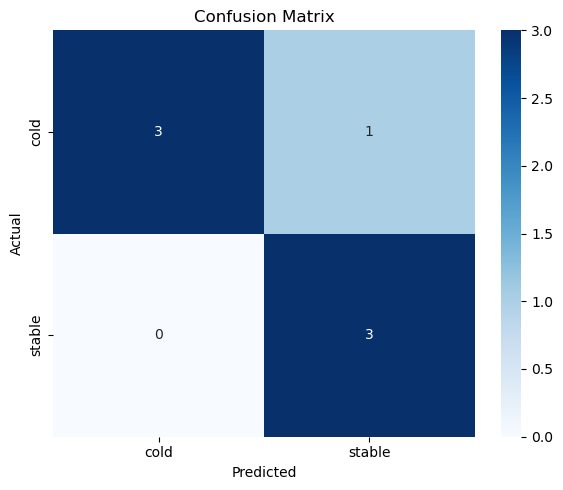

In [28]:
# Confusion matrix
cm = confusion_matrix(y_test_labels, y_pred_labels, labels=le.classes_)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

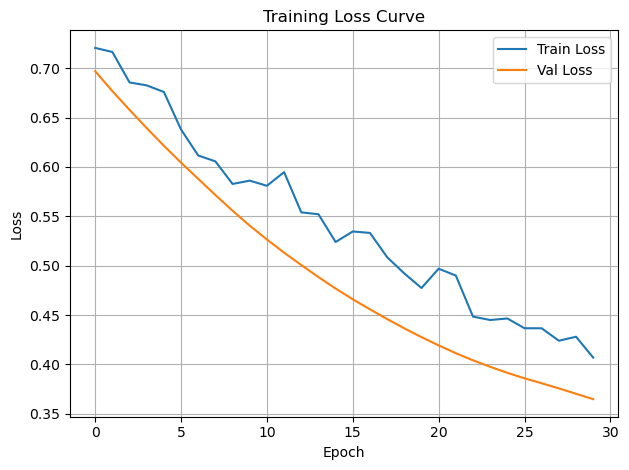

In [29]:
# Accuracy/loss plots
plt.figure()
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title("Training Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

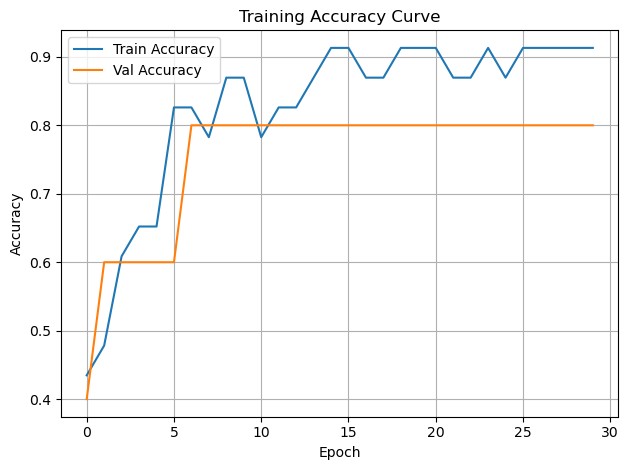

In [30]:
plt.figure()
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title("Training Accuracy Curve")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [31]:
classifier_model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 64)             │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,160 (4.54 KB)

 Trainable params: 386 (1.51 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 774 (3.03 KB)

In [ ]:
# Save model summary 
with open("classificationmodel_summary.txt", "w") as f:
    classifier_model.summary(print_fn=lambda line: f.write("[Classifier] " + line + "\n"))

print("Model summary saved to classificationmodel_summary.txt")

In [ ]:
# end of classifier variant demo